In [ ]:
# Introduction to Neural Networks & Multi-Layer Perceptrons (MLP)
# Dataset: Breast Cancer Wisconsin - built into sklearn, no download needed
#
# This uses sklearn's ready-made MLPClassifier - the practical, "just use it" way.
# For how backpropagation actually works under the hood, see the companion
# script: 31_backpropagation_from_scratch_xor.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df["target"] = cancer.target   # 0 = malignant, 1 = benign

print(df.shape)
print(df["target"].value_counts())

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---- 1. Scale features ----
# neural networks are VERY sensitive to feature scale - gradient descent
# struggles badly if one feature ranges 0-1 and another ranges 0-1000
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---- 2. Build a Multi-Layer Perceptron ----
# hidden_layer_sizes=(16, 8) means: input -> 16 neurons -> 8 neurons -> output
# this is the "multi-layer" part - more than just input and output layers
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

# ---- 3. Predict and evaluate ----
y_pred = mlp.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---- 4. Plot the training loss curve ----
# this is literally backpropagation at work - the network adjusting its
# weights after every batch to reduce this loss, iteration by iteration
plt.plot(mlp.loss_curve_)
plt.title("MLP Training Loss Over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print("Number of iterations until convergence:", mlp.n_iter_)
print("Number of layers (including input/output):", mlp.n_layers_)

# ---- 5. Try a couple of different architectures and compare ----
architectures = [
    (8,),           # 1 hidden layer, 8 neurons - simplest MLP
    (16, 8),        # 2 hidden layers
    (32, 16, 8),    # 3 hidden layers - deeper network
]

results = []
for arch in architectures:
    model = MLPClassifier(hidden_layer_sizes=arch, max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_scaled))
    results.append({"Architecture": str(arch), "Accuracy": acc, "Iterations": model.n_iter_})

results_df = pd.DataFrame(results)
print(results_df)

# a bigger/deeper network isn't automatically better - on a dataset this small
# and simple, a modest architecture often matches or beats a deep one, while
# training faster and overfitting less

# ---- 6. Effect of learning rate ----
# learning rate controls how big a step backpropagation takes when updating weights
learning_rates = [0.0001, 0.001, 0.01, 0.1]
lr_results = []

for lr in learning_rates:
    model = MLPClassifier(
        hidden_layer_sizes=(16, 8), learning_rate_init=lr,
        max_iter=500, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_scaled))
    lr_results.append({"Learning Rate": lr, "Accuracy": acc})

print(pd.DataFrame(lr_results))

# too small -> learns too slowly, may not converge in max_iter
# too large -> can overshoot and become unstable / fail to converge

In [1]:
# Introduction to Neural Networks & Multi-Layer Perceptrons (MLP)
# Dataset: Breast Cancer Wisconsin - built into sklearn, no download needed
#
# This uses sklearn's ready-made MLPClassifier - the practical, "just use it" way.
# For how backpropagation actually works under the hood, see the companion
# script: 31_backpropagation_from_scratch_xor.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_breast_cancer

In [2]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df["target"] = cancer.target   # 0 = malignant, 1 = benign

print(df.shape)
print(df["target"].value_counts())

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


(569, 31)
target
1    357
0    212
Name: count, dtype: int64


In [3]:
# ---- 1. Scale features ----
# neural networks are VERY sensitive to feature scale - gradient descent
# struggles badly if one feature ranges 0-1 and another ranges 0-1000
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---- 2. Build a Multi-Layer Perceptron ----
# hidden_layer_sizes=(16, 8) means: input -> 16 neurons -> 8 neurons -> output
# this is the "multi-layer" part - more than just input and output layers
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

# ---- 3. Predict and evaluate ----
y_pred = mlp.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.956140350877193

Confusion Matrix:
 [[41  1]
 [ 4 68]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



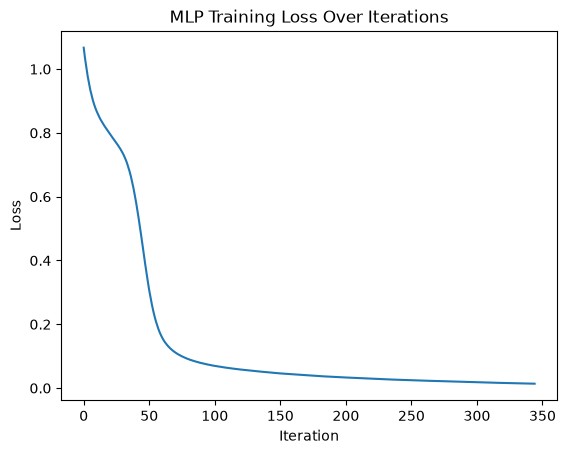

Number of iterations until convergence: 345
Number of layers (including input/output): 4


In [4]:
# ---- 4. Plot the training loss curve ----
# this is literally backpropagation at work - the network adjusting its
# weights after every batch to reduce this loss, iteration by iteration
plt.plot(mlp.loss_curve_)
plt.title("MLP Training Loss Over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print("Number of iterations until convergence:", mlp.n_iter_)
print("Number of layers (including input/output):", mlp.n_layers_)


In [5]:
# ---- 5. Try a couple of different architectures and compare ----
architectures = [
    (8,),           # 1 hidden layer, 8 neurons - simplest MLP
    (16, 8),        # 2 hidden layers
    (32, 16, 8),    # 3 hidden layers - deeper network
]

results = []
for arch in architectures:
    model = MLPClassifier(hidden_layer_sizes=arch, max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_scaled))
    results.append({"Architecture": str(arch), "Accuracy": acc, "Iterations": model.n_iter_})

results_df = pd.DataFrame(results)
print(results_df)

# a bigger/deeper network isn't automatically better - on a dataset this small
# and simple, a modest architecture often matches or beats a deep one, while
# training faster and overfitting less

  Architecture  Accuracy  Iterations
0         (8,)  0.964912         326
1      (16, 8)  0.956140         345
2  (32, 16, 8)  0.947368         203


In [6]:
# ---- 6. Effect of learning rate ----
# learning rate controls how big a step backpropagation takes when updating weights
learning_rates = [0.0001, 0.001, 0.01, 0.1]
lr_results = []

for lr in learning_rates:
    model = MLPClassifier(
        hidden_layer_sizes=(16, 8), learning_rate_init=lr,
        max_iter=500, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_scaled))
    lr_results.append({"Learning Rate": lr, "Accuracy": acc})

print(pd.DataFrame(lr_results))

# too small -> learns too slowly, may not converge in max_iter
# too large -> can overshoot and become unstable / fail to converge

C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


   Learning Rate  Accuracy
0         0.0001  0.921053
1         0.0010  0.956140
2         0.0100  0.956140
3         0.1000  0.973684
